# MEMC cvičení 2 – Pojišťovna

---

První „skutečná" úloha kurzu: pojišťovna vybere pojistné, během roku vyplácí škody a my chceme znát **pravděpodobnost úpadku** (škody převýší, co má k dispozici).

V sešitu uvidíte:

- jak z popisu reality udělat simulační model
- jak vypadá „papírový" odhad pomocí CLV
- proč je u téhle úlohy simulace lepší: **u aproximace z CLV nevíme, jak je přesná, u simulace to víme**

Úloha se sem vejde jen z poloviny. Nástroje, které potřebuje (inverzní transformace, geometrické mezery, uspořádané výběry, snižování rozptylu), se učíme v cvičeních 3 až 7. V **cvičení 9** se k pojišťovně vrátíme a dořešíme ji pořádně: intervaly spolehlivosti, vzácné úpadky a otázku „kolik kapitálu potřebujeme?".


In [1]:
import math
import random
import time

import matplotlib.pyplot as plt

random.seed(1)  # opakovatelné výsledky


def estimate(sampler, n):
    '''Běžné Monte Carlo: průměr n volání generátoru a jeho směrodatná chyba sigma/sqrt(n).'''
    s = s2 = 0.0
    for _ in range(n):
        x = sampler()
        s += x
        s2 += x * x
    mean = s / n
    var = max(s2 / n - mean * mean, 0.0)
    return mean, math.sqrt(var / n)


def check(name, mean, se, exact, k=5):
    '''Vypíše odhad a ověří, že leží do k směrodatných chyb od přesné hodnoty.'''
    print(f"{name}: {mezery(mean, ',.5g')} +- {mezery(se, ',.2g')}  (přesně {mezery(exact, ',.5g')})")
    assert abs(mean - exact) <= k * se, name


def Phi(x):
    '''Distribuční funkce N(0, 1).'''
    return 0.5 * (1 + math.erf(x / math.sqrt(2)))

def mezery(x, spec=","):
    '''Číslo s mezerami místo čárek jako oddělovač tisíců.'''
    return format(x, spec).replace(",", " ")

## 1. Model

Popis reality převedeme na model s několika předpoklady:

1. Rok rozdělíme na $N$ stejných intervalů (třeba dnů) tak malých, že se v jednom stane **nejvýše jeden** požadavek.
2. V každém intervalu je požadavek na plnění s pravděpodobností $p$, nezávisle na ostatních (Bernoulliho pokus).
3. Výše jednoho požadavku je $X = L\cdot R$, kde $L$ je maximální výplata a relativní výše $R \in [0, 1]$ má **hustotu $2r$**, tj. distribuční funkci $F(r) = r^2$. Hustota roste, takže velké škody jsou tedy častější než malé a střední hodnota je $E R = 2/3$.
4. Pojišťovna má k dispozici kapitál $K$ (počáteční kapitál plus vybrané pojistné). K úpadku dojde, když výplaty tento kapitál převýší.

Generátor pro $R$ vyrobíme **metodou inverzní transformace** (cvičení 4): z $F(r) = r^2$ plyne $F^{-1}(\gamma) = \sqrt{\gamma}$, takže $R = \sqrt{\gamma}$ s $\gamma \sim R(0,1)$.

**Šikovné pozorování:** výplaty jen přibývají, takže k úpadku někdy během roku dojde **právě tehdy, když celkové roční výplaty $T$ převýší $K$**. Stačí tedy simulovat $T$ a nemusíme sledovat průběh roku.

Dvě sady parametrů, se kterými budeme pracovat:

| | $N$ | $p$ | $L$ | $K$ | Charakter |
|---|-----|-----|-----|-----|-----------|
| Scénář A | 365 | 0.05 | 10 000 | 200 000 | úpadek je **vzácný** |
| Scénář B | 1000 | 0.15 | 100 000 | 10 000 000 | úpadek asi v polovině případů |

In [2]:
SCENAR_A = dict(N=365, p=0.05, L=10_000, K=200_000)
SCENAR_B = dict(N=1000, p=0.15, L=100_000, K=10_000_000)


def pozadavek(L):
    '''Výše jednoho požadavku: L * R, R má hustotu 2r na [0, 1] (inverzní transformace: R = sqrt(γ)).'''
    return L * math.sqrt(random.random())


def rocni_vyplaty_pomale(N, p, L):
    '''Doslovná simulace: projdeme všech N intervalů, v každém hodíme mincí s pravděpodobností p.'''
    T = 0.0
    for _ in range(N):
        if random.random() < p:
            T += pozadavek(L)
    return T

Jak model vypadá: vlevo rozdělení **jednoho požadavku** (hustota $2r$ a histogram vygenerovaných $R = \sqrt{\gamma}$), vpravo **několik simulovaných roků** ve scénáři A. Každý schod je jeden požadavek, křivka je kumulativní výplata, a pojišťovna zkrachuje, jakmile překročí kapitál $K$ (vodorovná čára). Ve scénáři A je překročení $K$ vzácné, proto k čáře většina křivek vůbec nedojde.

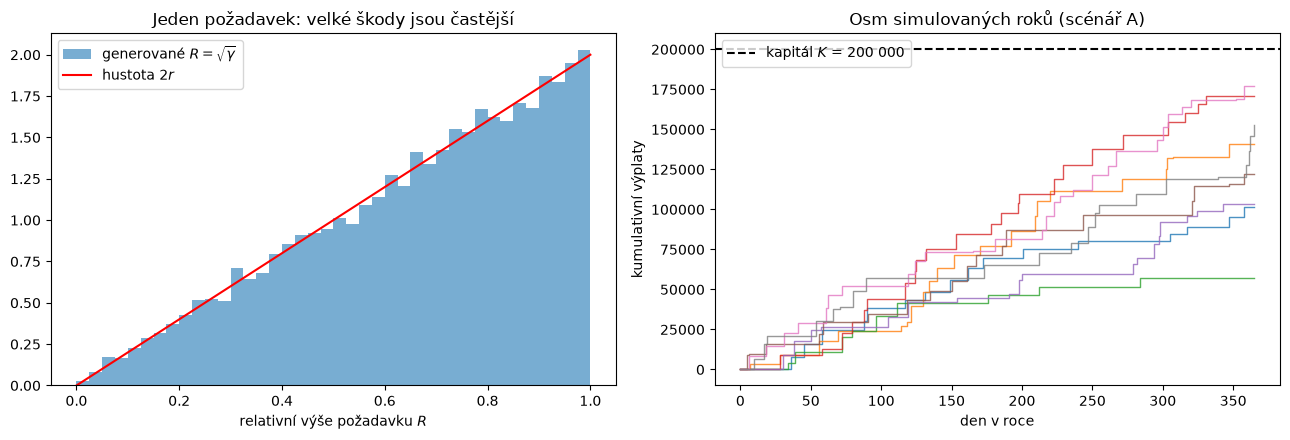

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# vlevo: relativní výše požadavku R = sqrt(γ) a hustota 2r
Rs = [math.sqrt(random.random()) for _ in range(20_000)]
axes[0].hist(Rs, bins=40, range=(0, 1), density=True, alpha=0.6, label="generované $R = \\sqrt{\\gamma}$")
axes[0].plot([0, 1], [0, 2], "r", label="hustota $2r$")
axes[0].set_xlabel("relativní výše požadavku $R$")
axes[0].set_title("Jeden požadavek: velké škody jsou častější")
axes[0].legend()

# vpravo: kumulativní výplaty během roku, scénář A
sc = SCENAR_A
ax = axes[1]
for beh in range(8):
    t_, kum, s = [0], [0.0], 0.0
    for den in range(1, sc["N"] + 1):
        if random.random() < sc["p"]:
            s += pozadavek(sc["L"])
        t_.append(den)
        kum.append(s)
    ax.step(t_, kum, where="post", lw=1, alpha=0.8)
ax.axhline(sc["K"], color="k", ls="--", label=f"kapitál $K$ = {mezery(sc['K'])}")
ax.set_xlabel("den v roce")
ax.set_ylabel("kumulativní výplaty")
ax.set_title("Osm simulovaných roků (scénář A)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 2. Přibližné řešení pomocí CLV

Roční výplata $T$ je součet $N$ nezávislých stejně rozdělených veličin $Y_i$ ($Y_i = X$ s pravděpodobností $p$, jinak $0$). Označíme-li $\mu = E X$ a $\sigma^2 = D X$, pak

$$E T = N p\mu, \qquad D T = N\big(p\sigma^2 + \mu^2 p(1-p)\big) = N\big(p\,E X^2 - p^2\mu^2\big).$$

Podle CLV je $T$ přibližně normální a

$$p_u = P(T > K) \approx 1 - \Phi\!\left(\frac{K - E T}{\sqrt{D T}}\right).$$

Pro náš model je $\mu = 2L/3$ a $E X^2 = L^2/2$. Jak dobrá aproximace to je, se **těžko odhaduje** (nevíme, jak velká je chyba CLV pro naše $N$). Simulace tento problém nemá.

In [4]:
def teorie(N, p, L, K):
    mu = 2 * L / 3
    EX2 = L * L / 2
    ET = N * p * mu
    VarT = N * (p * EX2 - (p * mu) ** 2)
    p_clv = 1 - Phi((K - ET) / math.sqrt(VarT))
    return ET, VarT, p_clv


for nazev, sc in (("A", SCENAR_A), ("B", SCENAR_B)):
    ET, VarT, p_clv = teorie(**sc)
    print(f"Scénář {nazev}: E T = {mezery(ET, ',.0f')},  sm. odchylka T = {mezery(math.sqrt(VarT), ',.0f')},  K = {mezery(sc['K'])},  "
          f"p_u (CLV) = {p_clv:.4f}")

Scénář A: E T = 121 667,  sm. odchylka T = 29 529,  K = 200 000,  p_u (CLV) = 0.0040
Scénář B: E T = 10 000 000,  sm. odchylka T = 806 226,  K = 10 000 000,  p_u (CLV) = 0.5000


## 3. Simulace

Doslovná simulace (jedna iterace na každý interval) je pomalá, ale přímo odpovídá modelu. Nejdřív ověříme, že generuje správné roční výplaty: střední hodnota a rozptyl musí odpovídat vzorcům výše.

In [5]:
sc = SCENAR_A
ET, VarT, _ = teorie(**sc)

n = 20_000
t0 = time.perf_counter()
m, se = estimate(lambda: rocni_vyplaty_pomale(sc["N"], sc["p"], sc["L"]), n)
t_pomale = (time.perf_counter() - t0) / n
check("E T", m, se, ET)
print(f"sm. odchylka T: simulace {mezery(se * math.sqrt(n), ',.0f')}, vzorec {mezery(math.sqrt(VarT), ',.0f')}")
print(f"čas na jednu simulaci roku: {t_pomale * 1e6:.0f} mikrosekund")

E T: 1.2177e+05 +- 2.1e+02  (přesně 1.2167e+05)
sm. odchylka T: simulace 29 361, vzorec 29 529
čas na jednu simulaci roku: 14 mikrosekund


## 4. Odhad pravděpodobnosti úpadku

Teď to hlavní. Pro každý z $M$ simulovaných roků si zapamatujeme, jestli došlo k úpadku:

$$\xi_i = \mathbf 1[T_i > K], \qquad \hat p = \frac{1}{M}\sum_{i=1}^M \xi_i .$$

$\xi_i$ je Bernoulliho veličina, takže $D\,\xi = p_u(1 - p_u)$ a směrodatná chyba odhadu je $\sqrt{\hat p(1-\hat p)/M}$. Vezmeme hrubý pás $\pm 2$ směrodatné chyby (podrobnosti o intervalech spolehlivosti jsou ve cvičení 9) a porovnáme s tím, co slibovala CLV.

In [6]:
M = 50_000
sc = SCENAR_A
N, p, L, K = sc["N"], sc["p"], sc["L"], sc["K"]

upadku = sum(rocni_vyplaty_pomale(N, p, L) > K for _ in range(M))
ph = upadku / M
se_ph = math.sqrt(ph * (1 - ph) / M)
p_clv = teorie(**sc)[2]

print(f"úpadků: {upadku} z {mezery(M)}")
print(f"simulace: p_u = {ph:.5f} +- {2 * se_ph:.5f}   (pás +- 2 sm. chyby: [{ph - 2 * se_ph:.5f}, {ph + 2 * se_ph:.5f}])")
print(f"CLV:      p_u = {p_clv:.5f}")
print(f"rozdíl je {abs(ph - p_clv) / se_ph:.1f} směrodatné chyby")

úpadků: 360 z 50 000
simulace: p_u = 0.00720 +- 0.00076   (pás +- 2 sm. chyby: [0.00644, 0.00796])
CLV:      p_u = 0.00399
rozdíl je 8.5 směrodatné chyby


### Proč je tady simulace lepší

Aproximace z CLV dává $p_u \approx 0.004$, simulace zhruba $0.007$ — a pás $\pm 2$ směrodatné chyby kolem simulace hodnotu z CLV **nepokrývá**. Rozdíl není náhoda vzorku.

Důvod: $T$ je součet **kladných** veličin a je zešikmený doprava. Normální aproximace má symetrické chvosty, takže pravý chvost podhodnocuje — a nás zajímá právě on.

Podstatné ale je něco jiného:

| | odhad | jak velkou dělá chybu |
|---|---|---|
| CLV | $1 - \Phi\big((K - E T)/\sqrt{D T}\big)$ | **nevíme** — CLV říká, že limita je normální, ne jak daleko od ní jsme při $N = 365$ |
| Simulace | $\hat p = \bar\xi_M$ | $\sqrt{\hat p(1-\hat p)/M}$, a dá se zmenšit zvětšením $M$ |

Tohle je hlavní důvod, proč se Monte Carlo vyplatí i tam, kde existuje vzorec: **chybu odhadu umíme změřit a umíme ji zmenšit.** U aproximace vzorcem ani jedno.

Pás $\pm 2$ směrodatné chyby je zatím hrubý: u vzácných jevů (malé $p_u$) selhává, protože $\hat p$ může vyjít i nula. Co s tím, je ve cvičení 9.

## Shrnutí

| Pojem | Co si pamatovat |
|-------|-----------------|
| Model | $N$ intervalů, požadavek s pravděpodobností $p$, výše $L\cdot\sqrt{\gamma}$ |
| Šikovné pozorování | výplaty jen přibývají ⟹ úpadek $\Leftrightarrow$ roční výplaty $T > K$; stačí simulovat $T$ |
| Aproximace z CLV | $p_u \approx 1 - \Phi\big((K - E T)/\sqrt{D T}\big)$; u zešikmeného $T$ podhodnocuje pravý chvost |
| Simulace | $\xi_i = \mathbf 1[T_i > K]$, $\hat p = \bar\xi$; žádná aproximace modelu |
| **Proč simulace** | u $\hat p$ známe směrodatnou chybu a umíme ji zmenšit; u CLV chybu aproximace neznáme |

### Zkuste si

1. Změňte rozdělení výše požadavku na $R = \gamma$ (rovnoměrné, $E R = 1/2$, $E R^2 = 1/3$). Upravte `teorie` a ověřte ji `check`em. Jak se změní $p_u$?
2. Zvyšte $N$ ve scénáři A (třeba $N = 3650$, $p = 0.005$, tedy stejný průměrný počet požadavků). Změní se $p_u$? Co to říká o kvalitě modelu s diskretizací roku?
3. Spočítejte, kolik běhů $M$ potřebujete, aby měl pás $\pm 2$ směrodatné chyby šířku nejvýše $10\,\%$ hodnoty $p_u$. (Napoví vzorec $\sqrt{p(1-p)/M}$ s $p \approx 0.007$.)
4. Pusťte `teorie` pro scénář B a porovnejte s krátkou simulací. Proč tam CLV sedí mnohem líp než u scénáře A?

---

**Pokračování ve cvičení 9**, kde na pojišťovnu použijeme všechno z cvičení 3–7: geometrické mezery (3), inverzní transformaci (4), uspořádané výběry (5) a snižování rozptylu pro vzácné úpadky (7).